# Payment Network Financial Performance & Risk Analytics

I compared Visa and Mastercard across FY2021-2025 using public financial statements. The notebook covers source-traced KPIs, profit and cash movements, debt context and illustrative scenarios.

Visa ends its fiscal year in September; Mastercard ends in December. Run the cells in order. The Excel model, Power BI report and decision memo are linked in README.


---

## Analysis section: Financial Eda


# Financial history EDA: Visa and Mastercard, FY2021-2025
Read the frozen Chapter05 SQL model, inspect scale and growth, and separate observations from unresolved explanations.

**Period control:** Visa ends September30; Mastercard ends December31. The same FY label is not the same calendar period.
**Source control:** no source refresh or database mutation. Figures show reported GAAP amounts. No adjusted growth, company ranking or causal claim.

Run cells from top to bottom. SQL selects data; pandas organizes tables; matplotlib draws figures. The saved notebook includes actual executed outputs.


In [1]:
import pandas as pd
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

from pathlib import Path
import os, sys, json, hashlib, sqlite3, platform
ROOT = Path.cwd().resolve()
if not (ROOT / 'models/payment_financials.sqlite').exists():
    ROOT = ROOT.parent
assert (ROOT / 'models/payment_financials.sqlite').exists(), 'Start Jupyter in the project root or notebooks folder'
for key, sub in [('MPLCONFIGDIR','mpl'),('IPYTHONDIR','ipython')]:
    folder = ROOT / 'data/work/06_runtime' / sub
    folder.mkdir(parents=True, exist_ok=True)
    os.environ[key] = str(folder)
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from financial_model import readonly
from financial_eda import summarize, rebase, growth
from financial_kpis import display as format_kpi
from fractions import Fraction
DB = ROOT / 'models/payment_financials.sqlite'
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
db_before = sha(DB)
runtime = {'python':platform.python_version(),'executable':sys.executable,'sqlite':sqlite3.sqlite_version,
           'pandas':pd.__version__,'numpy':np.__version__,'matplotlib':matplotlib.__version__}
print(runtime)
FIGURES = ROOT / 'reports/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.titleweight':'bold'})
COLORS = {'visa':'#155e75','mastercard':'#b45309'}
LABELS = {'visa':'Visa (Sep30 FY)','mastercard':'Mastercard (Dec31 FY)'}
MARKERS = {'visa':'o','mastercard':'s'}
FOOTNOTE = 'Source: frozen reviewed annual SQL inputs. FY labels retain issuer dates; no calendar normalization.'
def finish(fig, name):
    fig.text(.02,.02,FOOTNOTE,fontsize=9,color='#444444')
    fig.tight_layout(rect=(0,.07,1,.94))
    path = FIGURES / name
    fig.savefig(path,dpi=160,facecolor='white',metadata={'Software':'Project03 financial EDA'})
    plt.close(fig)
    display(Image(filename=str(path)))


{'python': '3.11.7', 'sqlite': '3.41.2', 'pandas': '2.1.4', 'numpy': '1.26.4', 'matplotlib': '3.8.0'}


## 1. Read the SQL model
Open the existing SQLite file in read-only mode. Preserve fiscal starts/ends and source identifiers. Do not sum publication-history records.


In [2]:
with readonly() as con:
    annual = pd.read_sql_query('SELECT * FROM v_annual_kpis ORDER BY company,fiscal_year', con)
    metrics = pd.read_sql_query('SELECT * FROM v_kpi_values ORDER BY company,fiscal_year,metric_id', con)
    sources = pd.read_sql_query('SELECT * FROM v_current_financial_items ORDER BY company,data_fiscal_year,item', con)
    revisions = pd.read_sql_query('SELECT * FROM v_revision_review ORDER BY company,period_id,item_id', con)
    lineage = pd.read_sql_query("""SELECT l.*,f.period_start,f.period_end,f.pdf_sha256,f.api_sha256,f.sec_url
      FROM v_kpi_lineage l JOIN v_current_financial_items f USING(observation_id)
      ORDER BY l.company,l.fiscal_year,l.metric_id,l.year_offset,l.item""", con)
display(annual[['company','fiscal_year','period_start','period_end','net_revenue','operating_income','operating_cash_flow']])


,company,fiscal_year,period_start,period_end,net_revenue,operating_income,operating_cash_flow
0,mastercard,2021,2021-01-01,2021-12-31,18884000000,10082000000,9463000000
1,mastercard,2022,2022-01-01,2022-12-31,22237000000,12264000000,11195000000
2,mastercard,2023,2023-01-01,2023-12-31,25098000000,14008000000,11980000000
3,mastercard,2024,2024-01-01,2024-12-31,28167000000,15582000000,14780000000
4,mastercard,2025,2025-01-01,2025-12-31,32791000000,18897000000,17648000000
5,visa,2021,2020-10-01,2021-09-30,24105000000,15804000000,15227000000
6,visa,2022,2021-10-01,2022-09-30,29310000000,18813000000,18849000000
7,visa,2023,2022-10-01,2023-09-30,32653000000,21000000000,20755000000
8,visa,2024,2023-10-01,2024-09-30,35926000000,23595000000,19950000000
9,visa,2025,2024-10-01,2025-09-30,40000000000,23994000000,23059000000


## 2. Check coverage before drawing
Expected: 10 company-years, 158 statement inputs, 280 KPI contexts and 457 statement operand references. A separate evidence table contains 30 operating-disclosure contexts. The only six unavailable results are first-year changes without a verified FY2020 base.

In [3]:
assert len(annual)==10 and not annual.duplicated(['company','fiscal_year']).any()
assert len(sources)==158 and not sources.duplicated(['company','data_fiscal_year','item']).any()
assert len(metrics)==280 and len(lineage)==457
assert metrics['status'].value_counts().to_dict()=={'defined':274,'undefined':6}
assert metrics.loc[metrics['status']!='defined','value'].isna().all()
assert set(metrics.loc[metrics['status']=='undefined','fiscal_year'])=={2021}
assert (metrics.loc[metrics['status']=='undefined','reason']=='missing_verified_prior_year').all()
display(metrics.groupby(['status','reason'],dropna=False).size().rename('contexts').reset_index())
print('The first-year change has no verified FY2020 base. All three industry metrics have verified issuer-specific series.')


The first-year change has no verified FY2020 base. All three industry metrics have verified issuer-specific series.


,status,reason,contexts
0,defined,NaN,274
1,undefined,missing_verified_prior_year,6


## 3. Add explicit exploratory descriptors
Revenue index = each issuer's revenue / its own FY2021 revenue *100.
CAGR = (FY2025 revenue / FY2021 revenue) ** (1/4) -1. Five annual observations contain **four growth intervals**.
These descriptors summarize endpoints; they do not replace each year's observed growth or imply currency-adjusted performance.


In [4]:
records = annual.to_dict('records')
summary = summarize(records)
annual['revenue_index_2021_100'] = np.nan
for company in ['visa','mastercard']:
    index = annual.index[annual['company']==company]
    annual.loc[index,'revenue_index_2021_100'] = [float(v) for v in rebase(annual.loc[index,'net_revenue'].tolist())]
summary_table = pd.DataFrame(summary).T[['first_revenue_usd','last_revenue_usd','cumulative_revenue_growth','revenue_cagr','last_revenue_index_2021_100']]
display(summary_table)
print('CAGR is a smoothed endpoint description, not an actual constant annual growth path.')


CAGR is a smoothed endpoint description, not an actual constant annual growth path.


,first_revenue_usd,last_revenue_usd,cumulative_revenue_growth,revenue_cagr,last_revenue_index_2021_100
visa,24105000000,40000000000,0.659407,0.13498,165.940676
mastercard,18884000000,32791000000,0.736444,0.147929,173.644355


## 4. Separate revenue scale from growth
The left panel keeps reported size. The right panel gives each issuer its own base100. Do not infer that larger revenue implies better performance, or that a rebased comparison aligns calendar periods.


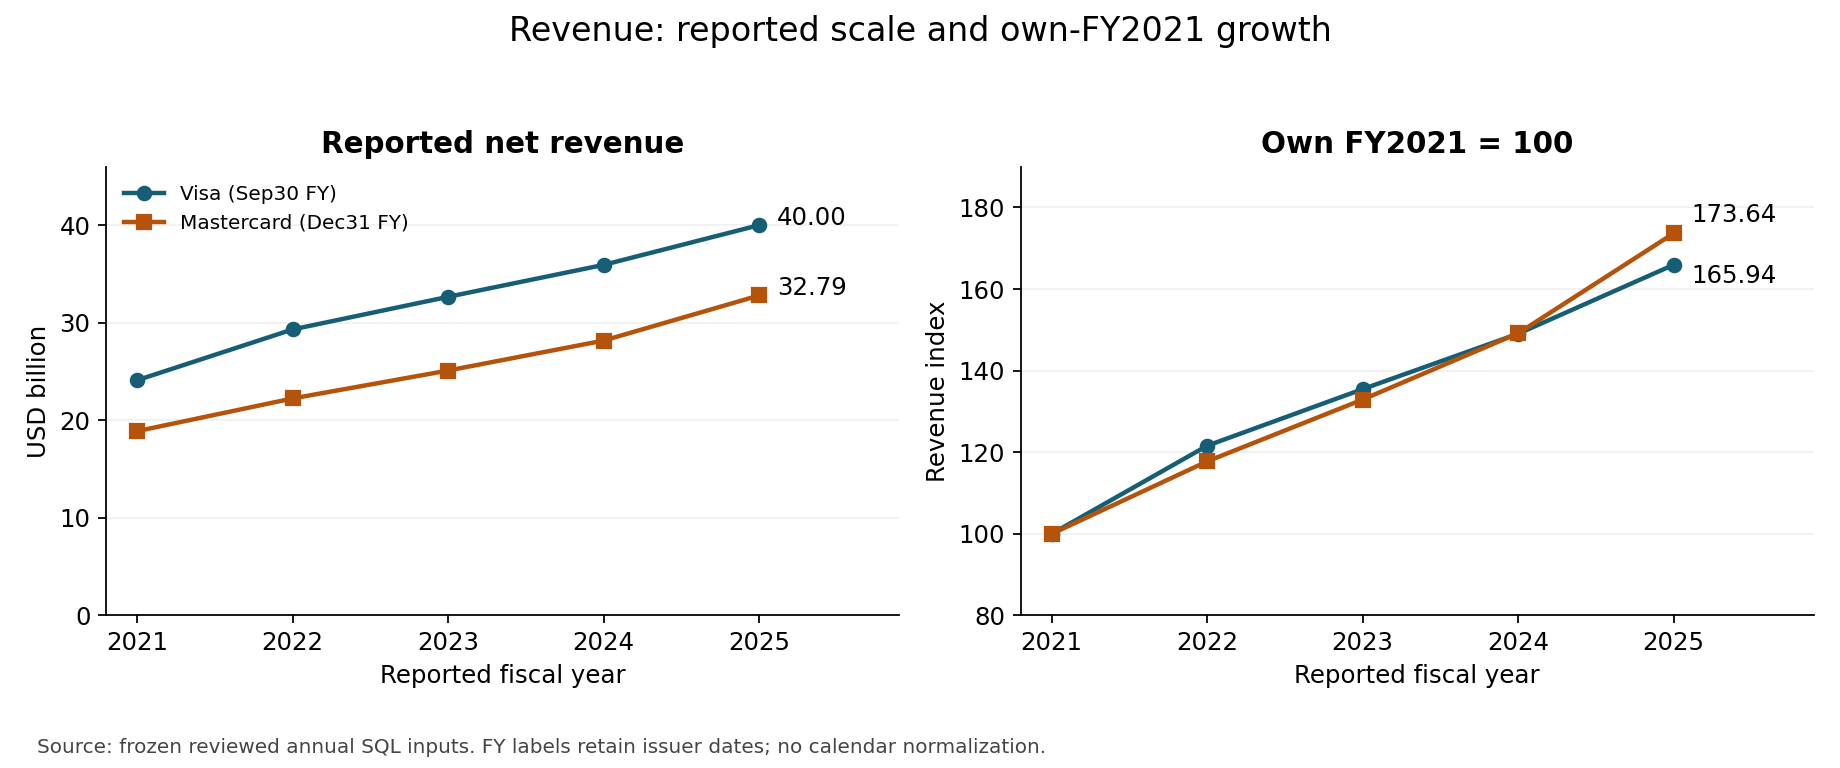

In [5]:
fig, axes = plt.subplots(1,2,figsize=(11.5,4.8))
fig.suptitle('Revenue: reported scale and own-FY2021 growth',fontsize=15)
for company in ['visa','mastercard']:
    frame=annual[annual['company']==company]
    for ax,values in [(axes[0],frame['net_revenue']/1e9),(axes[1],frame['revenue_index_2021_100'])]:
        ax.plot(frame['fiscal_year'],values,color=COLORS[company],marker=MARKERS[company],linewidth=2,label=LABELS[company])
        ax.set_xticks(range(2021,2026));ax.set_xlim(2020.8,2025.9)
        ax.set_xlabel('Reported fiscal year');ax.grid(axis='y',alpha=.18)
    axes[0].annotate(f"{frame.iloc[-1]['net_revenue']/1e9:.2f}",(2025,frame.iloc[-1]['net_revenue']/1e9),xytext=(8,0),textcoords='offset points')
    axes[1].annotate(f"{frame.iloc[-1]['revenue_index_2021_100']:.2f}",(2025,frame.iloc[-1]['revenue_index_2021_100']),xytext=(8,-8 if company=='visa' else 5),textcoords='offset points')
axes[0].set_title('Reported net revenue');axes[0].set_ylabel('USD billion');axes[0].set_ylim(0,46)
axes[1].set_title('Own FY2021 = 100');axes[1].set_ylabel('Revenue index');axes[1].set_ylim(80,190)
axes[0].legend(frameon=False,loc='upper left',fontsize=9)
finish(fig,'06_revenue_scale.png')


## 5. Compare revenue, cost and profit growth within each issuer
Margin = reported operating income / reported net revenue. The lower panels compare each issuer's own FY2025 with its own FY2024. This establishes an arithmetic relationship, not the economic cause of cost changes.


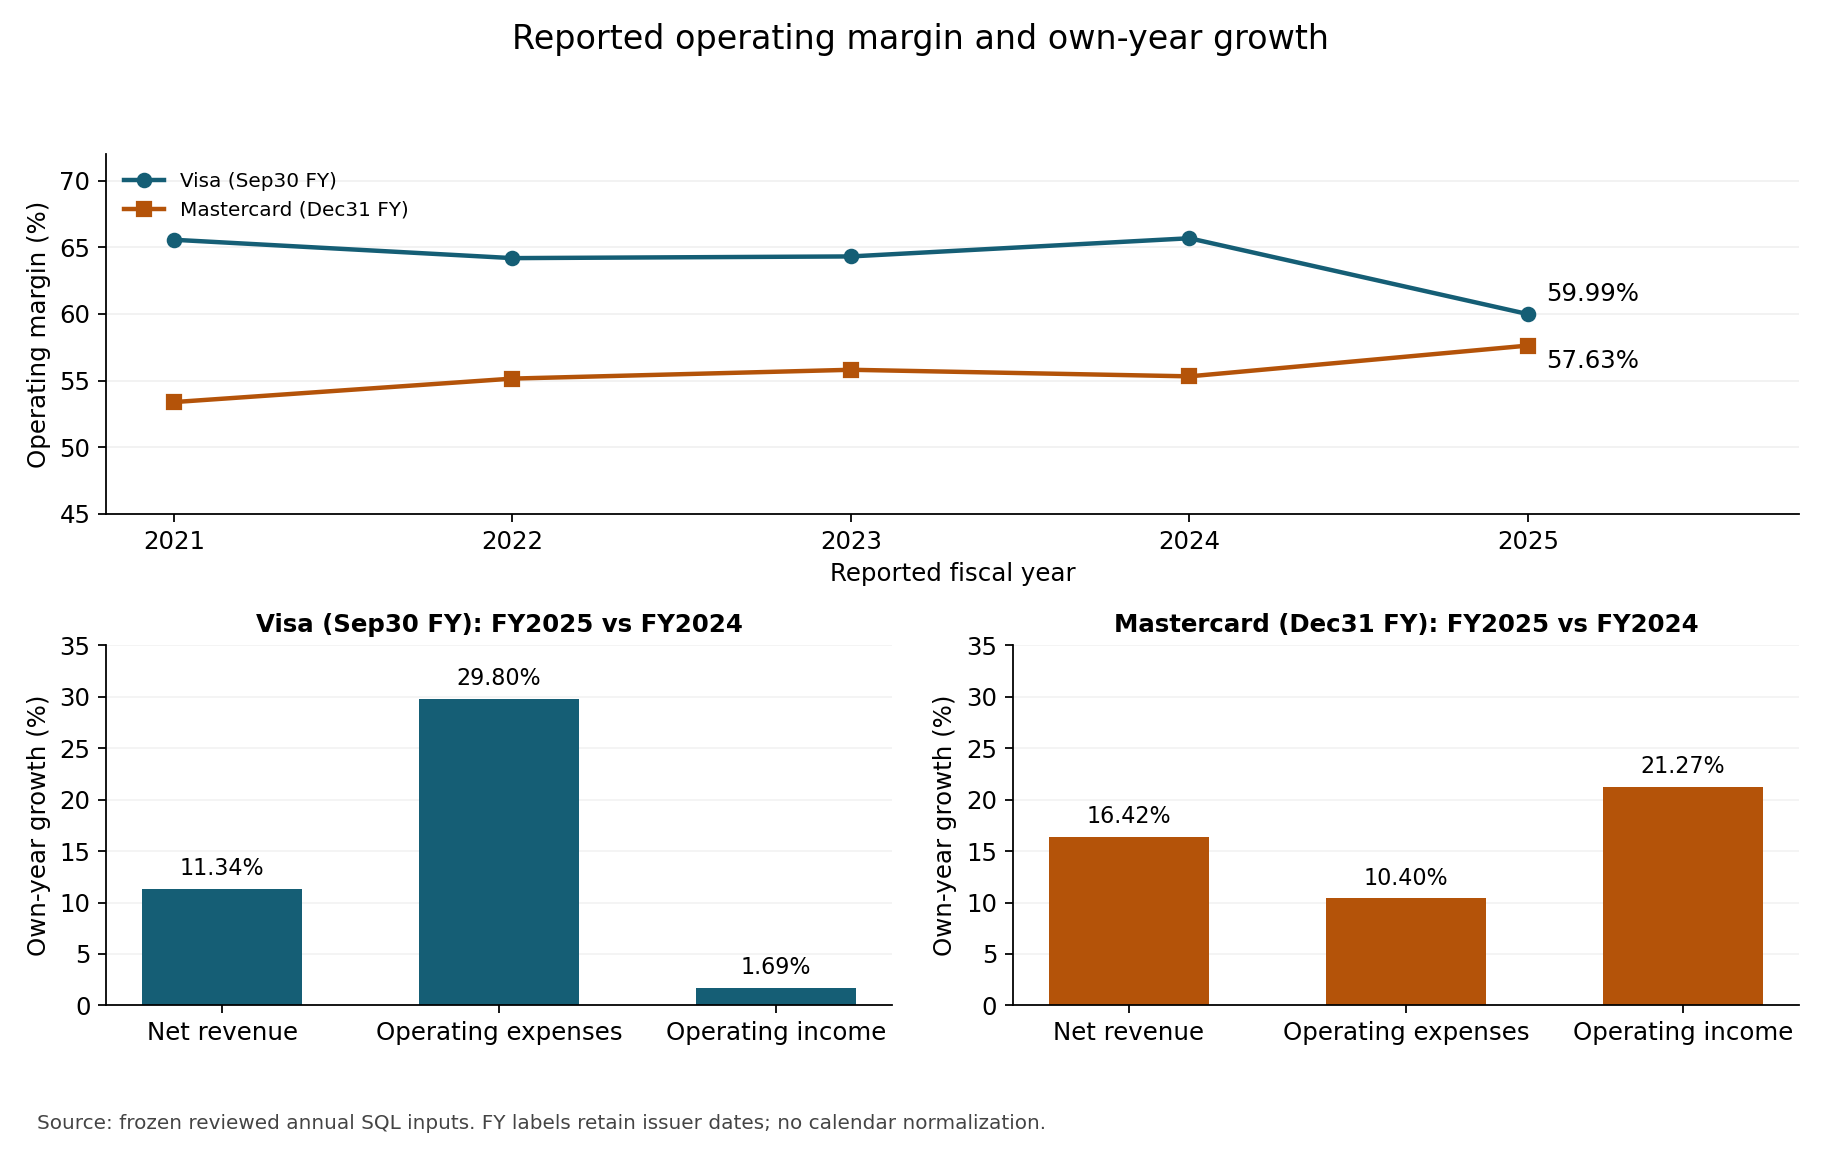

,fy2025_revenue_growth,fy2025_operating_expense_growth,fy2025_operating_income_growth,fy2025_operating_margin_change_pp
visa,0.1134,0.298029,0.01691,-5.691669
mastercard,0.164164,0.104013,0.212745,2.308562


In [6]:
fig=plt.figure(figsize=(11.5,7.2));grid=fig.add_gridspec(2,2)
top=fig.add_subplot(grid[0,:]);bottom=[fig.add_subplot(grid[1,0]),fig.add_subplot(grid[1,1])]
fig.suptitle('Reported operating margin and own-year growth',fontsize=15)
for company in ['visa','mastercard']:
    frame=annual[annual['company']==company]
    top.plot(frame['fiscal_year'],frame['operating_margin']*100,color=COLORS[company],marker=MARKERS[company],linewidth=2,label=LABELS[company])
    value=frame.iloc[-1]['operating_margin']*100
    exact_margin=Fraction(int(frame.iloc[-1]['operating_income']),int(frame.iloc[-1]['net_revenue']))
    top.annotate(format_kpi(exact_margin,'fraction'),(2025,value),xytext=(8,6 if company=='visa' else -10),textcoords='offset points')
top.set(xlim=(2020.8,2025.8),ylim=(45,72),xticks=range(2021,2026),ylabel='Operating margin (%)',xlabel='Reported fiscal year')
top.grid(axis='y',alpha=.18);top.legend(frameon=False,loc='upper left',fontsize=9)
for ax,company in zip(bottom,['visa','mastercard']):
    frame=annual[annual['company']==company]
    exact_growth=[growth(int(frame.iloc[-1][item]),int(frame.iloc[-2][item])) for item in ['net_revenue','operating_expenses','operating_income']]
    values=[float(100*x) for x in exact_growth]
    bars=ax.bar(['Net revenue','Operating expenses','Operating income'],values,color=COLORS[company],width=.58)
    ax.bar_label(bars,labels=[format_kpi(x,'fraction') for x in exact_growth],padding=4,fontsize=10)
    ax.set_title(LABELS[company]+': FY2025 vs FY2024',fontsize=11)
    ax.set_ylabel('Own-year growth (%)');ax.set_ylim(0,35);ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
finish(fig,'06_profitability.png')
display(pd.DataFrame(summary).T[['fy2025_revenue_growth','fy2025_operating_expense_growth','fy2025_operating_income_growth','fy2025_operating_margin_change_pp']])


## 6. Explore accounting income and operating cash
OCF and consolidated net income are both annual flows. Their ratio above1 is descriptive, not proof of sustainable earnings. Timing, working capital, taxes and disclosed unusual items require Chapter07 investigation.


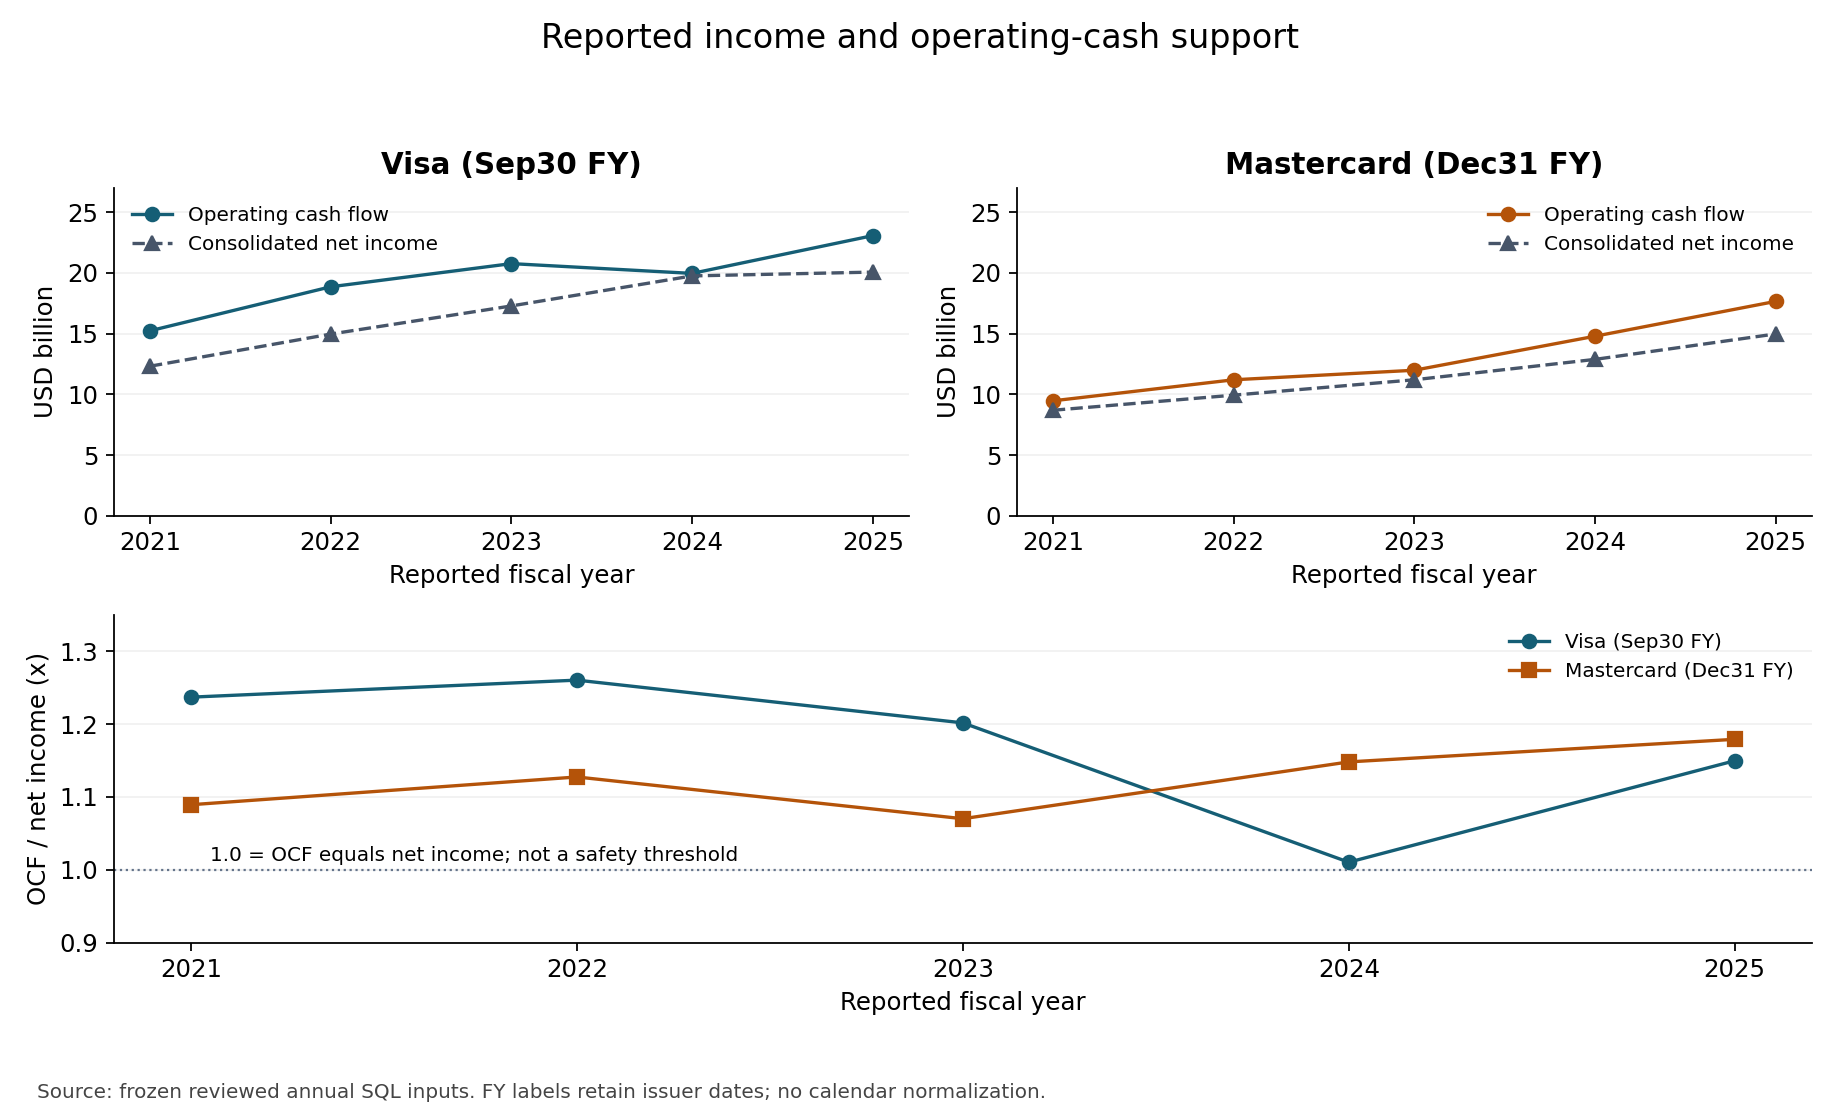

,cash_conversion_min,cash_conversion_max,fy2024_ocf_growth,fy2024_net_income_growth
visa,1.010485,1.260213,-0.038786,0.142998
mastercard,1.070121,1.179049,0.233723,0.149978


In [7]:
fig=plt.figure(figsize=(11.5,7.0));grid=fig.add_gridspec(2,2)
upper=[fig.add_subplot(grid[0,0]),fig.add_subplot(grid[0,1])];lower=fig.add_subplot(grid[1,:])
fig.suptitle('Reported income and operating-cash support',fontsize=15)
for ax,company in zip(upper,['visa','mastercard']):
    frame=annual[annual['company']==company]
    ax.plot(frame['fiscal_year'],frame['operating_cash_flow']/1e9,color=COLORS[company],marker='o',label='Operating cash flow')
    ax.plot(frame['fiscal_year'],frame['net_income']/1e9,color='#475569',marker='^',linestyle='--',label='Consolidated net income')
    ax.set(title=LABELS[company],ylabel='USD billion',ylim=(0,27),xticks=range(2021,2026),xlabel='Reported fiscal year')
    ax.grid(axis='y',alpha=.18);ax.legend(frameon=False,fontsize=9)
    lower.plot(frame['fiscal_year'],frame['cash_conversion'],color=COLORS[company],marker=MARKERS[company],label=LABELS[company])
lower.axhline(1,color='#64748b',linestyle=':',linewidth=1)
lower.text(2021.05,1.012,'1.0 = OCF equals net income; not a safety threshold',fontsize=9)
lower.set(ylabel='OCF / net income (x)',xlabel='Reported fiscal year',ylim=(.90,1.35),xticks=range(2021,2026))
lower.grid(axis='y',alpha=.18);lower.legend(frameon=False,fontsize=9,loc='upper right')
finish(fig,'06_cash_support.png')
display(pd.DataFrame(summary).T[['cash_conversion_min','cash_conversion_max','fy2024_ocf_growth','fy2024_net_income_growth']])


## 7. Distinguish unavailable bases, structural scope and operating-disclosure evidence
The raw-item grid has170 possible company/year/item slots but only158 declared applicable inputs. Visa software is included in its combined line; redeemable NCI is staged only for the declared issuer/years. Those12 out-of-scope slots are not invented zeros or missing verified inputs.


In [8]:
source_plan=json.loads((ROOT/'docs/03_reconciliation_plan.json').read_text())
raw_grid=[]
for company in ['visa','mastercard']:
    for year in range(2021,2026):
        for item in source_plan['items']:
            applicable=company in item['companies'] and year in item.get('applicable_years',range(2021,2026))
            raw_grid.append({'company':company,'fiscal_year':year,'item':item['id'],
                             'scope':'declared_applicable' if applicable else 'outside_declared_scope'})
raw_coverage=pd.DataFrame(raw_grid)
assert raw_coverage['scope'].value_counts().to_dict()=={'declared_applicable':158,'outside_declared_scope':12}
display(raw_coverage.groupby(['company','scope']).size().rename('slots').reset_index())
display(metrics[metrics['status']!='defined'].groupby(['metric_id','status','reason'],dropna=False).size().rename('contexts').reset_index())


,company,scope,slots
0,mastercard,declared_applicable,83
1,mastercard,outside_declared_scope,2
2,visa,declared_applicable,75
3,visa,outside_declared_scope,10


,metric_id,status,reason,contexts
0,net_revenue_yoy_growth,undefined,missing_verified_prior_year,2
1,operating_income_yoy_growth,undefined,missing_verified_prior_year,2
2,operating_margin_yoy_change,undefined,missing_verified_prior_year,2


## 8. Industry volumes, network transactions and revenue deductions

I used the operational supplements to align payment volume with each issuer's fiscal year. Both series exclude cash disbursements. Visa's June-end volume used to assess service revenue is a different measure and is excluded here.

Transaction counts preserve their original definitions: Visa processed transactions and Mastercard switched transactions. The plots show nominal count growth calculated from published amounts. They do not reproduce normalized issuer growth rates or remove the effect of the suspension in Russia.

Visa client incentives are reported amounts deducted from consolidated revenue. Mastercard's five-year series is derived as the sum of four payment-network assessments less payment-network net revenue, using the reclassified network scope. Its FY2023 result is USD15,181m, versus USD15,182m in the narrative, a USD1m rounding difference. The earlier company-wide rebate presentation is not combined with this series. Neither measure is cash paid.

Each amount below links to its PDF, page, source edition and hash in `references/industry_evidence.json`. Visa FY2021 processed transactions use the FY2023 comparative of 164,734m; the FY2021 report showed 164,733m. No common take-rate or average ticket is calculated from these differently scoped numerators and denominators.

All 30 operating contexts agree between the evidence ledger and SQLite. Mastercard deductions are derived from rounded network components; they are not company-wide reported rebates.


,company,fiscal_year,period_end,metric_id,value_in_source_units,source_scale,basis,scope
0,visa,2021,2021-09-30,payment_volume,10401.0,1000000000,reported_nominal_USD,"Worldwide Visa credit and debit payments, excluding cash"
1,visa,2021,2021-09-30,network_transactions,164734.0,1000000,reported,"Transactions processed on Visa networks, including payment and cash"
2,visa,2022,2022-09-30,payment_volume,11614.0,1000000000,reported_nominal_USD,"Worldwide Visa credit and debit payments, excluding cash"
3,visa,2022,2022-09-30,network_transactions,192530.0,1000000,reported,"Transactions processed on Visa networks, including payment and cash"
4,visa,2023,2023-09-30,payment_volume,12338.0,1000000000,reported_nominal_USD,"Worldwide Visa credit and debit payments, excluding cash"
5,visa,2023,2023-09-30,network_transactions,212579.0,1000000,reported,"Transactions processed on Visa networks, including payment and cash"
6,visa,2024,2024-09-30,payment_volume,13193.0,1000000000,reported_nominal_USD,"Worldwide Visa credit and debit payments, excluding cash"
7,visa,2024,2024-09-30,network_transactions,233758.0,1000000,reported,"Transactions processed on Visa networks, including payment and cash"
8,visa,2025,2025-09-30,payment_volume,14217.0,1000000000,reported_nominal_USD,"Worldwide Visa credit and debit payments, excluding cash"
9,visa,2025,2025-09-30,network_transactions,257545.0,1000000,reported,"Transactions processed on Visa networks, including payment and cash"


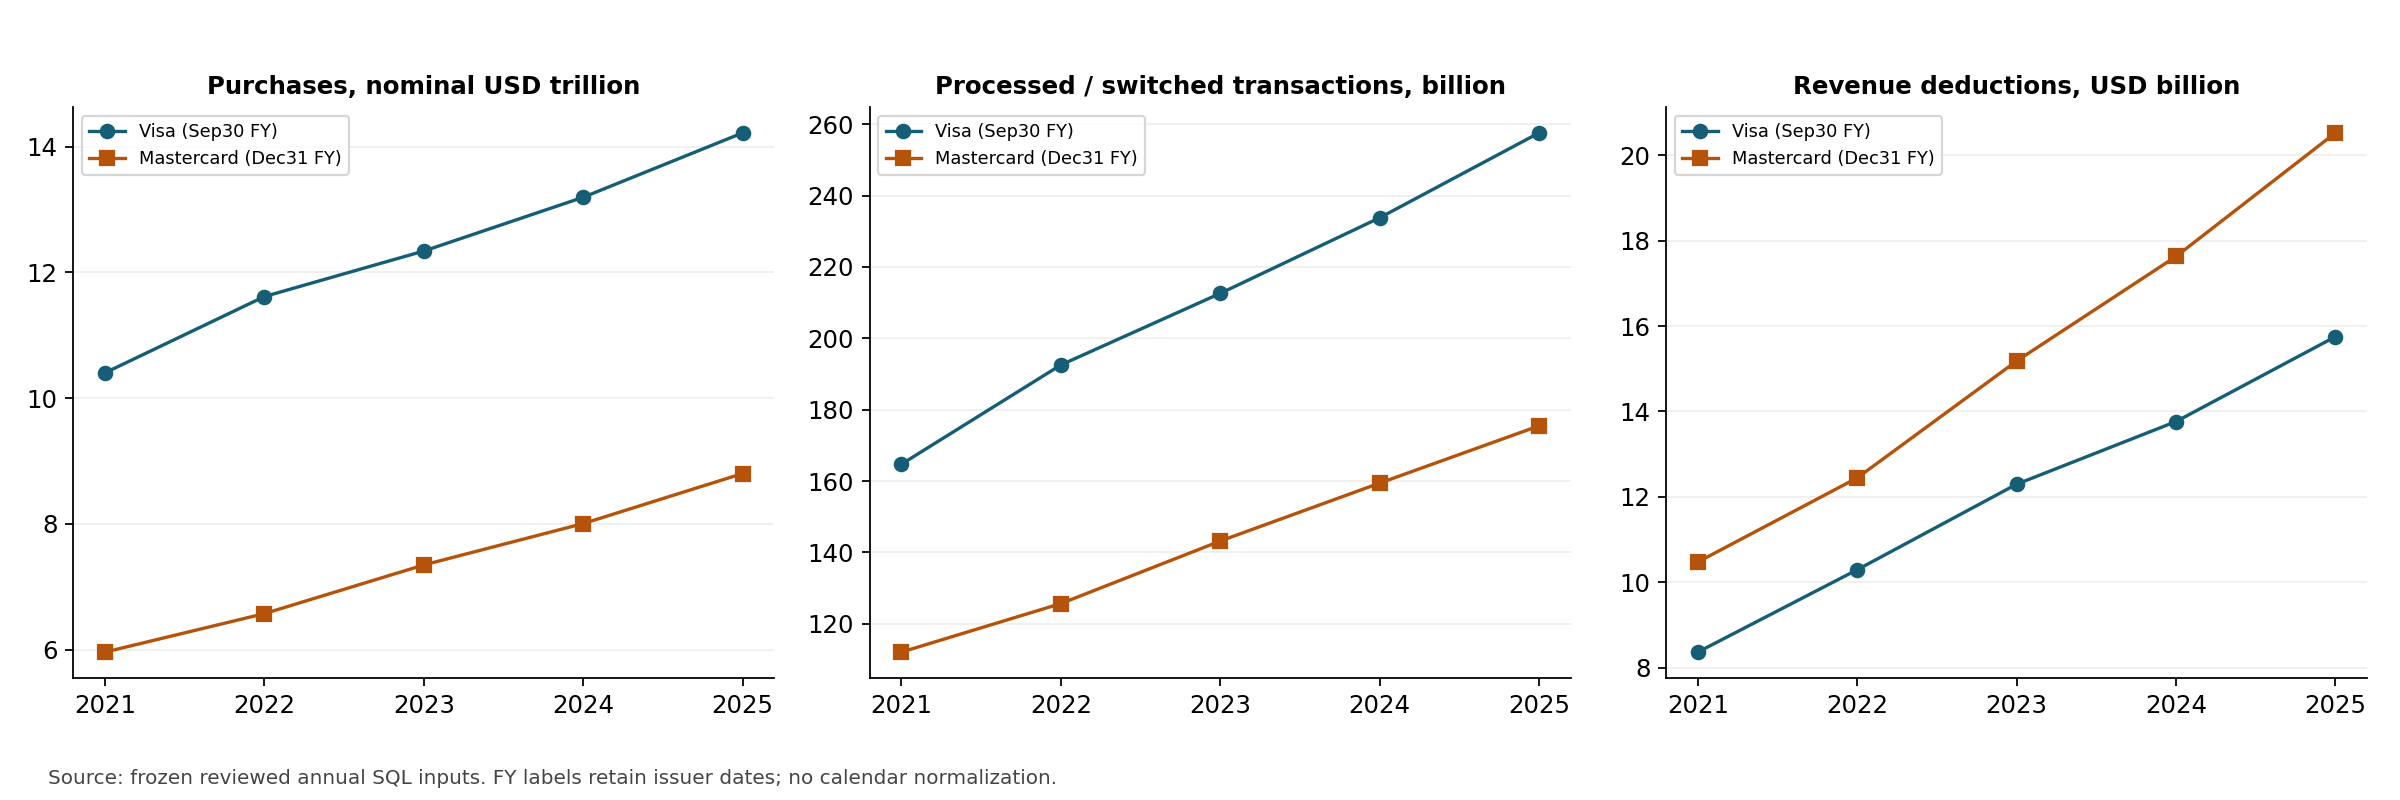

fiscal_year                                2024            2025  \
company    metric_id                                              
mastercard customer_incentives      17629000000     20522000000   
           network_transactions    159424000000    175464000000   
           payment_volume         8003000000000   8799000000000   
visa       customer_incentives      13764000000     15751000000   
           network_transactions    233758000000    257545000000   
           payment_volume        13193000000000  14217000000000   

fiscal_year                      own_fiscal_year_growth_pct  
company    metric_id                                         
mastercard customer_incentives                    16.410460  
           network_transactions                   10.061220  
           payment_volume                          9.946270  
visa       customer_incentives                    14.436210  
           network_transactions                   10.175908  
           payment_volume                          7.761692

,company,fiscal_year,gross_usdm,value_in_source_units,net_usdm,basis,narrative_reported_usdm,bridge_residual_usdm
20,visa,2021,32472.0,8367.0,24105.0,reported_contra_revenue_positive_magnitude,NaN,0.0
21,mastercard,2021,22419.0,10476.0,11943.0,derived_assessments_less_network_net_revenue,NaN,NaN
22,visa,2022,39605.0,10295.0,29310.0,reported_contra_revenue_positive_magnitude,NaN,0.0
23,mastercard,2022,26803.0,12445.0,14358.0,derived_assessments_less_network_net_revenue,NaN,NaN
24,visa,2023,44950.0,12297.0,32653.0,reported_contra_revenue_positive_magnitude,NaN,0.0
25,mastercard,2023,31005.0,15181.0,15824.0,derived_assessments_less_network_net_revenue,15182.0,-1.0
26,visa,2024,49690.0,13764.0,35926.0,reported_contra_revenue_positive_magnitude,NaN,0.0
27,mastercard,2024,34964.0,17629.0,17335.0,derived_assessments_less_network_net_revenue,NaN,NaN
28,visa,2025,55751.0,15751.0,40000.0,reported_contra_revenue_positive_magnitude,NaN,0.0
29,mastercard,2025,39998.0,20522.0,19476.0,derived_assessments_less_network_net_revenue,20522.0,0.0


,company,fiscal_year,metric_id,value,unit,basis,scope,pdf_path,pdf_pages,pdf_sha256,source_url
0,mastercard,2021,customer_incentives,10476000000,USD,derived_assessments_less_network_net_revenue,Mastercard payment-network revenue deductions; excludes value-added services and solutions,data/raw/issuer_reports/mastercard/FY2023_annual_report.pdf,"[55,56]",c68407a458406f18c0332f4a8ef0d08b7bd0c8b4a3f9da759d63509287737941,https://s25.q4cdn.com/479285134/files/doc_financials/2023/AR/2023-annual-report.pdf
1,mastercard,2021,network_transactions,112090000000,count,reported,Transactions initiated and switched through Mastercard network,data/raw/industry_supplements/mastercard_2021_supplement.pdf,[8],42303d911b189eb537bbcc0a81b1a7f8270b342a8a191f8b5641106a83e15e8f,https://investor.mastercard.com/files/doc_financials/2021/q4/4Q21-Mastercard-Supplemental-Operational-Performance-Data.pdf
2,mastercard,2021,payment_volume,5959000000000,USD,reported_nominal_USD,"Worldwide Mastercard credit, charge, debit and prepaid purchases, excluding cash, Maestro and Cirrus",data/raw/industry_supplements/mastercard_2021_supplement.pdf,[2],42303d911b189eb537bbcc0a81b1a7f8270b342a8a191f8b5641106a83e15e8f,https://investor.mastercard.com/files/doc_financials/2021/q4/4Q21-Mastercard-Supplemental-Operational-Performance-Data.pdf
3,mastercard,2022,customer_incentives,12445000000,USD,derived_assessments_less_network_net_revenue,Mastercard payment-network revenue deductions; excludes value-added services and solutions,data/raw/issuer_reports/mastercard/FY2023_annual_report.pdf,"[55,56]",c68407a458406f18c0332f4a8ef0d08b7bd0c8b4a3f9da759d63509287737941,https://s25.q4cdn.com/479285134/files/doc_financials/2023/AR/2023-annual-report.pdf
4,mastercard,2022,network_transactions,125680000000,count,reported,Transactions initiated and switched through Mastercard network,data/raw/industry_supplements/mastercard_2023_supplement.pdf,[8],c5ab30073e433a561eb8a3558e8d0a36f440b1f8932314e362aeb25460b16f85,https://s25.q4cdn.com/479285134/files/doc_financials/2023/q4/4Q23-Mastercard-Supplemental-Operational-Performance-Data.pdf
5,mastercard,2022,payment_volume,6571000000000,USD,reported_nominal_USD,"Worldwide Mastercard credit, charge, debit and prepaid purchases, excluding cash, Maestro and Cirrus",data/raw/industry_supplements/mastercard_2023_supplement.pdf,[2],c5ab30073e433a561eb8a3558e8d0a36f440b1f8932314e362aeb25460b16f85,https://s25.q4cdn.com/479285134/files/doc_financials/2023/q4/4Q23-Mastercard-Supplemental-Operational-Performance-Data.pdf
6,mastercard,2023,customer_incentives,15181000000,USD,derived_assessments_less_network_net_revenue,Mastercard payment-network revenue deductions; excludes value-added services and solutions,data/raw/issuer_reports/mastercard/FY2023_annual_report.pdf,"[55,56]",c68407a458406f18c0332f4a8ef0d08b7bd0c8b4a3f9da759d63509287737941,https://s25.q4cdn.com/479285134/files/doc_financials/2023/AR/2023-annual-report.pdf
7,mastercard,2023,network_transactions,143196000000,count,reported,Transactions initiated and switched through Mastercard network,data/raw/industry_supplements/mastercard_2023_supplement.pdf,[8],c5ab30073e433a561eb8a3558e8d0a36f440b1f8932314e362aeb25460b16f85,https://s25.q4cdn.com/479285134/files/doc_financials/2023/q4/4Q23-Mastercard-Supplemental-Operational-Performance-Data.pdf
8,mastercard,2023,payment_volume,7345000000000,USD,reported_nominal_USD,"Worldwide Mastercard credit, charge, debit and prepaid purchases, excluding cash, Maestro and Cirrus",data/raw/industry_supplements/mastercard_2023_supplement.pdf,[2],c5ab30073e433a561eb8a3558e8d0a36f440b1f8932314e362aeb25460b16f85,https://s25.q4cdn.com/479285134/files/doc_financials/2023/q4/4Q23-Mastercard-Supplemental-Operational-Performance-Data.pdf
9,mastercard,2024,customer_incentives,17629000000,USD,derived_assessments_less_network_net_revenue,Mastercard payment-network revenue deductions; excludes value-added services and solutions,data/raw/issuer_reports/mastercard/FY2025_annual_report

In [9]:
from industry_metrics import verified_rows
industry = pd.DataFrame(verified_rows())
assert len(industry)==30 and not industry.duplicated(['company','fiscal_year','metric_id']).any()
with readonly() as con:
    industry_sql = pd.read_sql_query('SELECT * FROM v_industry_lineage ORDER BY company,fiscal_year,metric_id', con)
    industry_values = pd.read_sql_query('SELECT * FROM fact_industry_metric', con)
for row in industry.to_dict('records'):
    got=industry_values[(industry_values.company==row['company']) & (industry_values.fiscal_year==row['fiscal_year']) & (industry_values.metric_id==row['metric_id'])]
    assert len(got)==1 and int(got.iloc[0]['value'])==row['value']
industry['value_in_source_units']=industry['value']/industry['source_scale']
display(industry[['company','fiscal_year','period_end','metric_id','value_in_source_units','source_scale','basis','scope']])
fig,axes=plt.subplots(1,3,figsize=(15,5))
for ax,metric,title,scale in zip(axes,['payment_volume','network_transactions','customer_incentives'],
        ['Purchases, nominal USD trillion','Processed / switched transactions, billion','Revenue deductions, USD billion'],[1e12,1e9,1e9]):
    for company in ['visa','mastercard']:
        frame=industry[(industry.company==company)&(industry.metric_id==metric)].sort_values('fiscal_year')
        ax.plot(frame.fiscal_year,frame.value/scale,marker=MARKERS[company],color=COLORS[company],label=LABELS[company])
    ax.set_title(title,fontsize=11);ax.set_xticks(range(2021,2026));ax.legend(fontsize=8);ax.grid(axis='y',alpha=.2)
finish(fig,'industry_history.png')
last=industry[industry.fiscal_year.isin([2024,2025])].pivot(index=['company','metric_id'],columns='fiscal_year',values='value')
last['own_fiscal_year_growth_pct']=(last[2025]/last[2024]-1)*100
display(last)
bridges=industry[industry.metric_id=='customer_incentives'][['company','fiscal_year','gross_usdm','value_in_source_units','net_usdm','basis','narrative_reported_usdm','bridge_residual_usdm']]
display(bridges)
display(industry_sql)
print('All 30 operating contexts agree between the evidence ledger and SQLite. Mastercard deductions are derived from rounded network components; they are not company-wide reported rebates.')

## 9. Trace findings to actual source inputs
Exploratory endpoint calculations carry explicit company/year/item keys. The source table preserves the original PDF and API hashes, pages, tags and publication identities. Fiscal labels never replace dates.


In [10]:
endpoint_keys={tuple(k) for s in summary.values() for k in s['endpoint_source_keys']}
trace=sources[sources.apply(lambda row:(row['company'],int(row['data_fiscal_year']),row['item']) in endpoint_keys,axis=1)]
assert len(trace)==4
display(trace[['company','data_fiscal_year','item','canonical_amount_usd','publication_accession','pdf_path','pdf_page','api_tag']])
display(revisions.groupby(['company','review_status']).size().rename('contexts').reset_index())
assert len(revisions[revisions['review_status']=='newer_api_same_amount_baseline_retained'])==49


,company,data_fiscal_year,item,canonical_amount_usd,publication_accession,pdf_path,pdf_page,api_tag
7,mastercard,2021,net_revenue,18884000000,0001141391-24-000022,data/raw/issuer_reports/mastercard/FY2023_annual_report.pdf,69,Revenues
74,mastercard,2025,net_revenue,32791000000,0001141391-26-000013,data/raw/issuer_reports/mastercard/FY2025_annual_report.pdf,69,Revenues
89,visa,2021,net_revenue,24105000000,0001403161-23-000099,data/raw/issuer_reports/visa/FY2023_annual_report.pdf,67,RevenueFromContractWithCustomerExcludingAssessedTax
149,visa,2025,net_revenue,40000000000,0001403161-25-000089,data/raw/issuer_reports/visa/FY2025_annual_report.pdf,75,RevenueFromContractWithCustomerExcludingAssessedTax


,company,review_status,contexts
0,mastercard,newer_api_same_amount_baseline_retained,26
1,mastercard,same_publication,57
2,visa,newer_api_same_amount_baseline_retained,23
3,visa,same_publication,52


## 10. Save reproducible tables and observations
The exported history is descriptive. No causal model, statistical significance, internal budget, scenario or recommendation is estimated. Operating-source definitions and derivations are retained in a separate evidence ledger.


In [11]:
out=ROOT/'data/processed';out.mkdir(parents=True,exist_ok=True)
annual.to_csv(out/'06_annual_history.csv',index=False)
metrics.to_csv(out/'06_metric_history.csv',index=False)
sources.to_csv(out/'06_source_items.csv',index=False)
lineage.to_csv(out/'06_metric_lineage.csv',index=False)
raw_coverage.to_csv(out/'06_raw_item_scope.csv',index=False)
result={'chapter':6,'status':'computed_historical_eda','model_sha256':db_before,
        'plan_sha256':sha(ROOT/'docs/06_eda_plan.json'),'runtime':runtime,
        'annual_company_years':len(annual),'raw_source_items':len(sources),'metric_contexts':len(metrics),
        'metric_statuses':metrics['status'].value_counts().to_dict(),'lineage_references':len(lineage),
        'raw_scope_slots':raw_coverage['scope'].value_counts().to_dict(),
        'company_summaries':summary,'industry_scope_review_sha256':sha(ROOT/'references/06_industry_scope_review.json'),
        'claims':'Reported own-fiscal-period observations only; no causal inference or normalized peer ranking. Industry series retain issuer-specific scope and PDF evidence.',
        'next_chapter':'07 Profitability and Cash Flow Quality'}
(ROOT/'reports/06_eda_results.json').write_text(json.dumps(result,ensure_ascii=False,indent=2,allow_nan=False)+chr(10))
print('Saved10 annual rows,280 metric contexts,158 source items and457 lineage references.')


Saved10 annual rows,280 metric contexts,158 source items and457 lineage references.


In [12]:
assert sha(DB)==db_before, 'Read-only SQL model changed'
for name in ['06_revenue_scale.png','06_profitability.png','06_cash_support.png']:
    assert (FIGURES/name).stat().st_size>10000
print('EDA execution completed. Source database unchanged. Next: Chapter07 disclosure-backed cash/profitability review.')


EDA execution completed. Source database unchanged. Next: Chapter07 disclosure-backed cash/profitability review.


## Reading the results
- Separate reported scale from own-base growth; retain the different fiscal dates.
- Visa's FY2025 revenue grew faster than operating income while operating expenses grew faster than revenue. Identify this arithmetic pattern; investigate disclosed costs next.
- OCF exceeded consolidated net income in all five annual observations for each issuer. Visa FY2024 nevertheless shows OCF falling while net income rose. This motivates investigation rather than a sustainability conclusion.
- Six first-year changes are undefined;30 issuer-specific industry KPI contexts are verified; six FY2021 changes lack a verified FY2020 base. The relevant disclosures are not automatically absent.
- Further work: Chapter07 tests cash/profitability explanations against the notes; later chapters handle risks, scenarios, Excel and Power BI.


## Profitability: reconcile the complete operating-income change

Visa FY2025 revenue growth did not translate into similar operating-income growth. The following values come from the reviewed statement-component ledger, in USD millions. A litigation provision is an expense, not cash paid.


In [13]:
components = pd.read_csv(ROOT / 'data/processed/07_statement_components.csv')
display(components.head())
display(pd.read_csv(ROOT / 'data/processed/07_bridge_changes.csv'))
display(pd.read_csv(ROOT / 'data/processed/07_metric_history.csv'))


,company,fiscal_year,item,role,section,source_label,source_token,source_signed_amount_usd,amount_usd,normalization,report_unit,pdf_path,pdf_page,pdf_line_index,pdf_sha256,source_url,publication_accession,source_basis
0,visa,2025,cost_1,operating_cost,all,Personnel,"6,961",6961000000,6961000000,signed,USD millions,data/raw/issuer_reports/visa/FY2025_annual_report.pdf,75,8,6111bd2f744c354164559f2dc292ff940dccde09dd2b7093ed6674b025189ab8,https://s29.q4cdn.com/385744025/files/doc_downloads/2025/Visa-Fiscal-2025-Annual-Report.pdf,0001403161-25-000089,Direct PDF row; closure/core anchors checked separately; not an individual API-match claim.
1,visa,2024,cost_1,operating_cost,all,Personnel,"6,264",6264000000,6264000000,signed,USD millions,data/raw/issuer_reports/visa/FY2025_annual_report.pdf,75,8,6111bd2f744c354164559f2dc292ff940dccde09dd2b7093ed6674b025189ab8,https://s29.q4cdn.com/385744025/files/doc_downloads/2025/Visa-Fiscal-2025-Annual-Report.pdf,0001403161-25-000089,Direct PDF row; closure/core anchors checked separately; not an individual API-match claim.
2,visa,2023,cost_1,operating_cost,all,Personnel,"5,831",5831000000,5831000000,signed,USD millions,data/raw/issuer_reports/visa/FY2025_annual_report.pdf,75,8,6111bd2f744c354164559f2dc292ff940dccde09dd2b7093ed6674b025189ab8,https://s29.q4cdn.com/385744025/files/doc_downloads/2025/Visa-Fiscal-2025-Annual-Report.pdf,0001403161-25-000089,Direct PDF row; closure/core anchors checked separately; not an individual API-match claim.
3,visa,2025,cost_2,operating_cost,all,Marketing,"1,684",1684000000,1684000000,signed,USD millions,data/raw/issuer_reports/visa/FY2025_annual_report.pdf,75,9,6111bd2f744c354164559f2dc292ff940dccde09dd2b7093ed6674b025189ab8,https://s29.q4cdn.com/385744025/files/doc_downloads/2025/Visa-Fiscal-2025-Annual-Report.pdf,0001403161-25-000089,Direct PDF row; closure/core anchors checked separately; not an individual API-match claim.
4,visa,2024,cost_2,operating_cost,all,Marketing,"1,560",1560000000,1560000000,signed,USD millions,data/raw/issuer_reports/visa/FY2025_annual_report.pdf,75,9,6111bd2f744c354164559f2dc292ff940dccde09dd2b7093ed6674b025189ab8,https://s29.q4cdn.com/385744025/files/doc_downloads/2025/Visa-Fiscal-2025-Annual-Report.pdf,0001403161-25-000089,Direct PDF row; closure/core anchors checked separately; not an individual API-match claim.


,bridge,group,change_usd,component_items,meaning
0,visa_2023_to_2024_ocf,net_income,2470000000,net_income,"Change in reported OCF reconciliation rows, not gross payments"
1,visa_2023_to_2024_ocf,net_incentive_reconciliation,-1586000000,client_incentives_adjustment;client_incentives_change,"Change in reported OCF reconciliation rows, not gross payments"
2,visa_2023_to_2024_ocf,net_settlement_reconciliation,20000000,settlement_receivable;settlement_payable,"Change in reported OCF reconciliation rows, not gross payments"
3,visa_2023_to_2024_ocf,accrued_other_liabilities,-1967000000,accrued_other_liabilities,"Change in reported OCF reconciliation rows, not gross payments"
4,visa_2023_to_2024_ocf,remaining_reconciliation_items,258000000,accounts_payable;accounts_receivable;accrued_litigation;deferred_tax;depreciation_amortization;equity_gains_losses;other_adjustment;other_assets;share_compensation;ve_covered_losses,"Change in reported OCF reconciliation rows, not gross payments"


,company,fiscal_year,period_start,period_end,operating_margin,net_margin,cash_conversion,operating_cash_flow,net_income,capital_payments_defined,fcf_proxy,fcf_proxy_margin
0,mastercard,2021,2021-01-01,2021-12-31,0.533891,0.460019,1.089329,9463000000,8687000000,814000000,8649000000,0.458007
1,mastercard,2022,2022-01-01,2022-12-31,0.551513,0.446553,1.127392,11195000000,9930000000,1097000000,10098000000,0.454108
2,mastercard,2023,2023-01-01,2023-12-31,0.558132,0.446051,1.070121,11980000000,11195000000,1088000000,10892000000,0.433979
3,mastercard,2024,2024-01-01,2024-12-31,0.553201,0.457060,1.148050,14780000000,12874000000,1194000000,13586000000,0.482337
4,mastercard,2025,2025-01-01,2025-12-31,0.576286,0.456467,1.179049,17648000000,14968000000,1215000000,16433000000,0.501144
5,visa,2021,2020-10-01,2021-09-30,0.655632,0.510724,1.236861,15227000000,12311000000,705000000,14522000000,0.602448
6,visa,2022,2021-10-01,2022-09-30,0.641863,0.510304,1.260213,18849000000,14957000000,970000000,17879000000,0.609997
7,visa,2023,2022-10-01,2023-09-30,0.643126,0.528987,1.201586,20755000000,17273000000,1059000000,19696000000,0.603191
8,visa,2024,2023-10-01,2024-09-30,0.656767,0.549546,1.010485,19950000000,19743000000,1257000000,18693000000,0.520320
9,visa,2025,2024-10-01,2025-09-30,0.599850,0.501450,1.149616,23059000000,20058000000,1482000000,21577000000,0.539425


## Cash and debt: investigation rather than a safety score

Read cash, selected carrying debt and their difference together. Carrying debt is not a principal maturity schedule. Directional flags are investigation prompts, not loss probabilities.


In [14]:
risk_history = pd.read_csv(ROOT / 'data/processed/08_risk_history.csv')
display(risk_history)
signals = pd.read_csv(ROOT / 'data/processed/08_change_signals.csv')
display(signals[signals['fiscal_year'] == 2025] if 'fiscal_year' in signals else signals.head(12))


,company,fiscal_year,period_start,period_end,cash_and_cash_equivalents,current_debt,noncurrent_debt,debt_carrying_total,net_debt_cash_equivalents_proxy,cash_to_debt_ratio,debt_to_assets,operating_margin,cash_conversion
0,mastercard,2021,2021-01-01,2021-12-31,7421000000,792000000,13109000000,13901000000,6480000000,0.533846,0.369030,0.533891,1.089329
1,mastercard,2022,2022-01-01,2022-12-31,7008000000,274000000,13749000000,14023000000,7015000000,0.499750,0.362127,0.551513,1.127392
2,mastercard,2023,2023-01-01,2023-12-31,8588000000,1337000000,14344000000,15681000000,7093000000,0.547669,0.369417,0.558132,1.070121
3,mastercard,2024,2024-01-01,2024-12-31,8442000000,750000000,17476000000,18226000000,9784000000,0.463184,0.379069,0.553201,1.148050
4,mastercard,2025,2025-01-01,2025-12-31,10566000000,749000000,18251000000,19000000000,8434000000,0.556105,0.350832,0.576286,1.179049
5,visa,2021,2020-10-01,2021-09-30,16487000000,999000000,19978000000,20977000000,4490000000,0.785956,0.253052,0.655632,1.236861
6,visa,2022,2021-10-01,2022-09-30,15689000000,2250000000,20200000000,22450000000,6761000000,0.698842,0.262570,0.641863,1.260213
7,visa,2023,2022-10-01,2023-09-30,16286000000,0,20463000000,20463000000,4177000000,0.795875,0.226113,0.643126,1.201586
8,visa,2024,2023-10-01,2024-09-30,11975000000,0,20836000000,20836000000,8861000000,0.574726,0.220461,0.656767,1.010485
9,visa,2025,2024-10-01,2025-09-30,17164000000,5569000000,19602000000,25171000000,8007000000,0.681896,0.252652,0.599850,1.149616


company  fiscal_year               signal_id                label_en  \
24        visa         2025           cash_decrease       Cash balance down   
25        visa         2025           debt_increase        Selected debt up   
26        visa         2025   current_debt_increase         Current debt up   
27        visa         2025       net_debt_increase      Debt-minus-cash up   
28        visa         2025         margin_decrease   Operating margin down   
29        visa         2025  ocf_growth_lags_income  OCF growth < NI growth   
54  mastercard         2025           cash_decrease       Cash balance down   
55  mastercard         2025           debt_increase        Selected debt up   
56  mastercard         2025   current_debt_increase         Current debt up   
57  mastercard         2025       net_debt_increase      Debt-minus-cash up   
58  mastercard         2025         margin_decrease   Operating margin down   
59  mastercard         2025  ocf_growth_lags_income  OCF growth < NI growth   

          status reason comparison     operand_a     operand_b operand_unit  \
24  not_observed    NaN          <  1.716400e+10  1.197500e+10          USD   
25      observed    NaN          >  2.517100e+10  2.083600e+10          USD   
26      observed    NaN          >  5.569000e+09  0.000000e+00          USD   
27  not_observed    NaN          >  8.007000e+09  8.861000e+09          USD   
28      observed    NaN          <  5.998500e-01  6.567667e-01     fraction   
29  not_observed    NaN          <  1.558396e-01  1.595502e-02     fraction   
54  not_observed    NaN          <  1.056600e+10  8.442000e+09          USD   
55      observed    NaN          >  1.900000e+10  1.822600e+10          USD   
56  not_observed    NaN          >  7.490000e+08  7.500000e+08          USD   
57  not_observed    NaN          >  8.434000e+09  9.784000e+09          USD   
58  not_observed    NaN          <  5.762862e-01  5.532006e-01     fraction   
59  not_observed    NaN          <  1.940460e-01  1.626534e-01     fraction   

      difference    difference_unit  \
24  5.189000e+09                USD   
25  4.335000e+09                USD   
26  5.569000e+09                USD   
27 -8.540000e+08                USD   
28 -5.691669e+00  percentage_points   
29  1.398846e-01           fraction   
54  2.124000e+09                USD   
55  7.740000e+08                USD   
56 -1.000000e+06                USD   
57 -1.350000e+09                USD   
58  2.308562e+00  percentage_points   
59  3.139260e-02           fraction   

                                                                                          meaning  \
24  Directional pattern only; not observed does not mean safe, and observed is not a probability.   
25  Directional pattern only; not observed does not mean safe, and observed is not a probability.   
26  Directional pattern only; not observed does not mean safe, and observed is not a probability.   
27  Directional pattern only; not observed does not mean safe, and observed is not a probability.   
28  Directional pattern only; not observed does not mean safe, and observed is not a probability.   
29  Directional pattern only; not observed does not mean safe, and observed is not a probability.   
54  Directional pattern only; not observed does not mean safe, and observed is not a probability.   
55  Directional pattern only; not observed does not mean safe, and observed is not a probability.   
56  Directional pattern only; not observed does not mean safe, and observed is not a probability.   
57  Directional pattern only; not observed does not mean safe, and observed is not a probability.   
58  Directional pattern only; not observed does not mean safe, and observed is not a probability.   
59  Directional pattern only; not observed does not mean safe, and observed is not a probability.   

                                                                                                                                 

## Recalculate illustrative scenarios

Revenue and margin assumptions are author-chosen examples, not forecasts or company budgets. Expenses are implied by revenue minus operating income.


In [15]:
from peer_scenarios import margin_scenario
visa = annual[(annual['company'] == 'visa') & (annual['fiscal_year'] == 2025)].iloc[0]
illustrations = []
for name, growth, margin in [('Base', '0.10', '0.60'), ('Downside', '0.04', '0.56'), ('Upside', '0.14', '0.62')]:
    values = margin_scenario(int(visa['net_revenue']), int(visa['operating_expenses']), growth, margin)
    illustrations.append({'case': name, 'growth': float(growth), 'margin': float(margin), 'revenue_USDm': float(values['revenue']) / 1e6, 'operating_income_USDm': float(values['operating_income']) / 1e6})
scenario_comparison = pd.DataFrame(illustrations)
display(scenario_comparison)
assert scenario_comparison['operating_income_USDm'].tolist() == [26400.0, 23296.0, 28272.0]


,case,growth,margin,revenue_USDm,operating_income_USDm
0,Base,0.10,0.60,44000.0,26400.0
1,Downside,0.04,0.56,41600.0,23296.0
2,Upside,0.14,0.62,45600.0,28272.0


## Decision and deliverables

Before a current briefing, reconcile subsequent filings. Before explaining profit changes, inspect cost/legal and tax/cash components. Before a funding conclusion, reconcile available cash and principal maturities. Industry volume, transactions and revenue deductions are covered in section 8. Read the scope and derivation before comparing issuers.

Open `Financial_KPI_and_Scenario_Model.xlsx`, `Payment_Financials.pbix`, and [the decision memo](reports/11_financial_memo.md).
